# Steam : analyse du marché du jeu vidéo avec PySpark

*Certification RNCP35288 (Concepteur Développeur en Science des Données), bloc 2 : étude
d'une base de données massive et semi-structurée avec un traitement parallélisé (Spark).*

**Contexte (scénario de l'étude de cas)** : Ubisoft prépare un nouveau jeu et demande une analyse globale du
catalogue Steam pour comprendre l'écosystème et les tendances. **Question** : quels facteurs
sont associés à la popularité ou aux ventes d'un jeu ? L'analyse suit trois
niveaux : *macro* (éditeurs, jeux les mieux notés, sorties par année et effet du Covid, prix
et remises, langues, restrictions d'âge), *genres* (représentation, avis, genres favoris des
éditeurs, genres lucratifs) et *plateformes* (Windows, Mac, Linux).

**Données** : `steam_game_output.json` (63,7 Mo, 55 691 enregistrements, dont 55 690 jeux), jeu de
données de l'étude de cas, non versionné dans ce dépôt (voir `donnees/LIRE_DONNEES.md`).
Chaque enregistrement contient un
identifiant et un objet `data` imbriqué : nom, éditeur, développeur, genres et langues (texte
séparé par des virgules), plateformes (structure de booléens), avis positifs et négatifs, prix en
**cents de dollar US** (format SteamSpy), tranche de propriétaires, date de sortie, âge requis,
catégories (liste) et *tags* (structure de 441 champs : votes des joueurs par étiquette).

**Plan** : 1. Session Spark et lecture ; 2. Aplatissement, nettoyage, audit ; 3. Analyse macro ;
4. Genres ; 5. Plateformes ; 6. Analyse multivariée ; 7. Efficacité du traitement parallélisé ;
8. Recommandations pour Ubisoft et limites ; 9. Conformité RGPD ; 10. Exécution sur Databricks.

| Critère du référentiel (bloc 2) | Section |
|---|---|
| Analyse d'une base de données massive et déstructurée avec Spark | 1, 2, 7 |
| Pertinence de la méthodologie de nettoyage ; clarté et disponibilité des données | 2 |
| Analyses univariées et multivariées | 3 à 6 |
| Traitement parallélisé via Spark ; efficacité du traitement parallélisé appliqué | 7 |
| Clarté et simplicité des graphiques ; présentation à un public profane | 3 à 6 |
| Pertinence des recommandations | 8 |
| Conformité au RGPD | 9 |

---

### Documentation vivante du notebook

### CHOIX

- **Retenu** : Spark pour lire le JSON imbriqué et l'aplatir (`getField`, `explode`, fenêtres),
  une table propre mise en cache, des agrégations calculées en un seul passage, et une
  expérience de parallélisme à protocole fixe (un essai de chauffe, cinq essais chronométrés
  affichés, médiane retenue) dont le résultat est recoupé avec pandas, tag par tag.
- **Retenu** : le nettoyage et les outils de mesure vivent dans `steam_analyse.py`, une fonction
  par défaut réel du fichier, testées à part sur de petits enregistrements
  (`tests/test_steam_analyse.py`) ; le notebook garde le raisonnement, les agrégations et les
  graphiques.
- **Écarté** : imputer les valeurs manquantes (inventer un éditeur ou une date fausserait les
  comptages), classer les jeux par part d'avis positifs brute (un jeu à 100 % sur 50 avis
  passerait devant un jeu à 98 % sur 100 000 : on classe par borne de Wilson), et comparer les
  genres sur un revenu médian par jeu (effet de découpage des tranches de propriétaires,
  expliqué en section 4.4).
- **Écarté** : `display()` appelé depuis le module (invisible d'un module sur Databricks : le
  notebook la passe en paramètre) et une session Spark créée à l'import du module.

### OÙ

- Dossier `2_Steam/`. Le notebook lit `donnees/steam_game_output.json` en local (63,7 Mo, fichier non
  versionné dans ce dépôt : voir `donnees/LIRE_DONNEES.md`) ou le stockage S3 sur Databricks, et importe
  `steam_analyse.py` (même dossier ; sur Databricks, à déposer avec le notebook). Il n'a pas
  d'appelant : c'est un livrable que le jury relit.
- Dépendances : pyspark 3.5.9 avec Java fourni par `jdk4py` (aucune installation système), setuptools (le `toPandas()` de Spark 3.5 importe `distutils`, retiré de Python 3.12), pandas,
  matplotlib ; pour les tests, pytest, nbclient et ipykernel. Versions épinglées dans
  `requirements.txt`.
- Fichiers voisins : `donnees/` (`LIRE_DONNEES.md` ; le fichier de données n'est pas versionné),
  `captures/` (sorties de l'exécution locale, fournies à la place de la publication
  Databricks), `tests/`.

### COMMENT

1. « Restart & Run All » dans le dossier du notebook : exécution locale complète en quelques
   minutes (la section 7 répète un calcul lourd 6 réglages x 6 fois) ; la durée varie avec la
   charge de la machine.
2. Sections 1 et 2 : session, lecture, aplatissement, audit, nettoyage. Sections 3 à 6 : analyses
   macro, genres, plateformes, multivariée. Section 7 : parallélisme. Sections 8 à 10 :
   recommandations, RGPD, Databricks.
3. Tests qui le prouvent : `tests/test_steam_analyse.py` (cas calculés à la main sur des
   enregistrements qui reproduisent les défauts du fichier, refus des entrées interdites) et
   `tests/test_notebook_steam.py` (le notebook exécuté de bout en bout redonne les chiffres du
   jury ; sans les données, il échoue au chargement).
4. Typage : mypy --strict ne lit pas les notebooks ; il est donc mesuré sur l'export .py de leurs
   cellules de code (« mesuré hors notebook »), et le module `steam_analyse.py` est vérifié en direct.

### POURQUOI

- Borne de Wilson et part de gros succès avec intervalle : justification en section 4.4 ; le
  calcul est vérifié à la main dans `tests/test_steam_analyse.py` ; implémentation
  `2_Steam/steam_analyse.py:285`.
- Regroupement des écritures d'un éditeur (« Ubisoft », « Ubisoft Entertainment »,
  « Ubisoft® », « Ubisoft - San Francisco » comptent ensemble) : cas relevés dans le fichier ;
  implémentation `2_Steam/steam_analyse.py:353`, preuve
  `tests/test_steam_analyse.py:779`.
- Les deux moteurs doivent rendre les mêmes totaux avant d'être comparés en temps :
  `2_Steam/steam_analyse.py:567` refuse toute différence, prouvé par
  `tests/test_steam_analyse.py:250` ; l'accélération est la médiane à une partition
  divisée par la médiane du réglage (`tests/test_steam_analyse.py:188`).
- Captures de sorties à la place de la publication Databricks : consigne de l'étude de cas,
  rappelée en section 10 de ce notebook.
- Les chiffres des cellules d'interprétation sont ceux des sorties de ce notebook ;
  `tests/test_notebook_steam.py:89` contrôle ceux qui ne dépendent pas de la machine (les
  durées de la section 7 en dépendent et ne sont pas figées).

### JOURNALISATION

- Le notebook affiche (`print`, `show`) chaque comptage de nettoyage et chaque résultat ; il
  n'emploie pas le module `logging`. Le niveau de journal de Spark est réglé à `ERROR`
  (`setLogLevel`) : seuls les échecs de Spark apparaissent.
- `steam_analyse.py` ne journalise rien : une entrée interdite lève une exception (`ValueError` ou
  `TypeError`) que le notebook laisse remonter ; une cellule en erreur arrête l'exécution.
- Le plan d'exécution affiché ne contient aucun chemin de machine (`plan_sans_chemin_de_machine`
  refuse un plan où il en reste un).


## 1. Session Spark et lecture des données

Le notebook s'exécute **à l'identique sur Databricks et en local**. Sur Databricks, la session
Spark (`spark`) et la fonction `display()` existent déjà ; en local, on crée une session
`local[*]` (un seul exécuteur, donc une seule JVM, avec autant de fils d'exécution que de
cœurs logiques du processeur ; le « parallélisme par défaut » affiché plus bas compte ces fils)
avec un Java portable fourni par le paquet `jdk4py`. Seuls le chemin des données et l'affichage
des graphiques changent.

Les fonctions de nettoyage et de mesure sont dans `steam_analyse.py`, importé par la cellule 2 et testé à part (`tests/test_steam_analyse.py`) : sur Databricks, ce fichier doit être déposé avec le notebook, dans le même dossier de l'espace de travail.

In [1]:
import contextlib
import io
import time
from functools import partial

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import Window
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType

# Fonctions extraites du notebook pour être testées (tests/test_steam_analyse.py) : session,
# nettoyage, éditeurs, graphiques, expérience de parallélisme. Chaque fonction est décrite dans
# steam_analyse.py ; le raisonnement reste dans les cellules Markdown.
from steam_analyse import (
    SEPARATEUR_EDITEURS,
    ajouter_champs_derives,
    aplatir_jeux,
    champs_struct,
    chemin_donnees,
    chronometrer,
    comparer_votes,
    editeurs_par_jeu,
    montrer_graphique,
    obtenir_spark,
    plan_sans_chemin_de_machine,
    premiere_ligne,
    reglages_partitions,
    sur_databricks,
    tableau_acceleration,
    votes_par_tag,
    wilson,
)

# Sur Databricks, la variable d'environnement DATABRICKS_RUNTIME_VERSION existe toujours : c'est
# le moyen fiable de savoir où l'on s'exécute.
SUR_DATABRICKS = sur_databricks()
CHEMIN_DONNEES = chemin_donnees(SUR_DATABRICKS)

# Session Spark : celle de Databricks, ou une session locale[*] (Java fourni par jdk4py, interface
# web désactivée, 8 partitions de brassage au lieu de 200) ; voir obtenir_spark.
spark = obtenir_spark(SUR_DATABRICKS)
spark.sparkContext.setLogLevel("ERROR")
# Spark 3 : une date qui ne correspond à aucun motif donne NULL (comptée dans l'audit) au lieu
# d'interrompre le traitement.
spark.conf.set("spark.sql.legacy.timeParserPolicy", "CORRECTED")
print("Spark", spark.version, "| exécution :", "Databricks" if SUR_DATABRICKS else "locale")
print("Parallélisme par défaut (cœurs disponibles) :", spark.sparkContext.defaultParallelism)

Spark 3.5.9 | exécution : locale
Parallélisme par défaut (cœurs disponibles) : 24


In [2]:
# Lecture du JSON. Spark déduit le schéma imbriqué en parcourant le fichier ; on mesure le temps.
debut = time.perf_counter()
brut = spark.read.json(CHEMIN_DONNEES)
nb_lignes = brut.count()
print(
    f"{nb_lignes:,} enregistrements lus en {time.perf_counter() - debut:.1f} s".replace(",", " ")
)
print("Partitions du DataFrame brut :", brut.rdd.getNumPartitions())

# Schéma : on affiche les champs de 'data' sauf le détail des 441 tags, illisible.
champs_data = champs_struct(brut.schema, "data")
for champ in champs_data:
    if champ.name == "tags":
        nb_tags = len(champs_struct(brut.schema, "data", "tags"))
        print(f" - tags : structure de {nb_tags} champs (votes par étiquette)")
    else:
        print(f" - {champ.name} : {champ.dataType.simpleString()}")

55 691 enregistrements lus en 5.0 s
Partitions du DataFrame brut : 16
 - appid : bigint
 - categories : array<string>
 - ccu : bigint
 - developer : string
 - discount : string
 - genre : string
 - header_image : string
 - initialprice : string
 - languages : string
 - name : string
 - negative : bigint
 - owners : string
 - platforms : struct<linux:boolean,mac:boolean,windows:boolean>
 - positive : bigint
 - price : string
 - publisher : string
 - release_date : string
 - required_age : string
 - short_description : string
 - tags : structure de 441 champs (votes par étiquette)
 - type : string
 - website : string


## 2. Aplatissement, nettoyage et audit de qualité

Le schéma est **imbriqué** : on extrait les champs utiles de `data` (`getField` via la notation
pointée), on convertit les types, puis on construit des DataFrames dédiés pour les champs à
valeurs multiples (genres, langues, catégories) avec `split` puis `explode` : une ligne par
couple (jeu, genre). Décisions de nettoyage, chacune justifiée dans le code :

- texte vide (`""`) pour l'éditeur ou le développeur → valeur manquante (sinon « vide » serait
  compté comme un éditeur) ;
- prix et prix initial en cents de dollar → dollars ;
- tranche de propriétaires « 20,000 .. 50,000 » → bornes numériques et point milieu ;
- date : trois formats réels (`2021/05/14`, `2000/11/1`, `2019/01`) et des dates vides ;
- langues : quatre fiches contiennent des balises de mise en forme (`[b]*[/b]`, retours à la
  ligne) qui créeraient de fausses langues (« German[b]*[/b] ») → balises retirées ; une liste
  vide compte pour 0 langue (et non 1) ;
- éditeurs : un même éditeur s'écrit de plusieurs façons (« Ubisoft », « Ubisoft
  Entertainment », « Ubisoft® », « Ubisoft - San Francisco ») et un jeu peut avoir plusieurs
  éditeurs (« Cyan Worlds Inc, Ubisoft ») → noms normalisés et table une ligne par (jeu,
  éditeur) ;
- un enregistrement de type `hardware` (matériel, pas un jeu) → écarté.

In [3]:
# Aplatissement (aplatir_jeux, steam_analyse.py) : champs utiles de « data », texte vide -> NULL
# pour l'éditeur et le développeur, prix en cents de dollar -> dollars.
jeux = aplatir_jeux(brut)

# Champs dérivés (ajouter_champs_derives, steam_analyse.py), chacun motivé par un défaut réel :
# - langues : balises de mise en forme ([b], [/b], *) et retours à la ligne retirés ; une liste
#   vide compte pour 0 langue ;
# - date : trois formats réels (yyyy/M/d et yyyy/M) ; une date vide ou inconnue devient NULL ;
# - propriétaires : tranche « 20,000 .. 50,000 » -> bornes numériques et point milieu ;
# - avis : total, part positive et borne basse de Wilson (95 %), qui classe honnêtement les jeux :
#   100 % sur 50 avis n'est pas « meilleur » que 98 % sur 100 000 ;
# - âge requis : au-delà de 21 ans (180, 35 : vus dans l'audit), erreur de saisie -> NULL.
jeux = ajouter_champs_derives(jeux)
print(
    "Âges requis aberrants (> 21 ans) mis à NULL :",
    jeux.filter(F.col("age_requis_brut") > 21).count(),
)
jeux = jeux.drop("age_requis_brut")
print("Colonnes de la table aplatie :", len(jeux.columns))

Âges requis aberrants (> 21 ans) mis à NULL : 5
Colonnes de la table aplatie : 31


In [4]:
# Audit de qualité : nombre de valeurs manquantes de chaque colonne, calculé en UN SEUL passage
# sur les données (une agrégation par colonne dans le même select) : c'est la façon efficace de
# procéder avec Spark, au lieu d'une requête par colonne.
manquants = (
    jeux.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in jeux.columns]).toPandas().T
)
manquants.columns = ["valeurs_manquantes"]
print(manquants[manquants["valeurs_manquantes"] > 0])
print("appid en double :", jeux.count() - jeux.select("appid").distinct().count())
print("types d'enregistrement :", jeux.groupBy("type").count().collect())
print("jeux gratuits (prix initial nul) :", jeux.filter(F.col("prix_initial_usd") == 0).count())
print("jeux sans aucun avis :", jeux.filter(F.col("total_avis") == 0).count())

               valeurs_manquantes
developpeur                   127
editeur                       134
date_sortie                    99
annee                          99
mois                           99
part_positive                 163
score_wilson                  163
age_requis                      8


appid en double : 0


types d'enregistrement : [Row(type='hardware', count=1), Row(type='game', count=55690)]


jeux gratuits (prix initial nul) : 7780


jeux sans aucun avis : 163


In [5]:
# Décisions : on ne garde que les jeux (un enregistrement 'hardware' est écarté) ; les valeurs
# manquantes restent NULL (Spark les ignore dans les agrégats) et ne sont pas imputées : inventer
# un éditeur ou une date fausserait les comptages.
jeux = jeux.filter(F.col("type") == "game").drop("type")

# cache() garde la table en mémoire après le premier calcul : les dizaines d'agrégations qui
# suivent ne relisent plus le JSON (63 Mo) ni ne recalculent les conversions.
jeux.cache()
print(f"Jeux retenus : {jeux.count():,}".replace(",", " "))

# Tables dédiées aux champs multivalués : une ligne par (jeu, valeur).
genres = jeux.select("appid", F.explode(F.split("genres_texte", r",\s*")).alias("genre")).filter(
    F.col("genre") != ""
)
langues = jeux.select("appid", F.explode("langues").alias("langue"))
print("Lignes (jeu, genre) :", genres.count(), "| lignes (jeu, langue) :", langues.count())
print("Jeux sans aucune langue renseignée :", jeux.filter(F.col("nb_langues") == 0).count())

Jeux retenus : 55 690


Lignes (jeu, genre) : 157110 | lignes (jeu, langue) : 202293
Jeux sans aucune langue renseignée : 10


In [6]:
# Table (jeu, éditeur) avec noms normalisés. Trois étapes, chacune motivée par un cas réel :
# 1. découper les éditeurs multiples sur la virgule, sauf quand elle précède une forme sociale
#    (« Foo, Inc. » reste un seul éditeur), « Cyan Worlds Inc, Ubisoft » donne deux éditeurs ;
# 2. retirer les symboles ®, ™, © et la mention d'un studio après un tiret entouré d'espaces
#    (« Ubisoft - San Francisco » → « Ubisoft ») ;
# 3. retirer les formes sociales et le mot « Entertainment » en fin de nom (« Ubisoft
#    Entertainment », « Strategy First Inc. »), puis comparer sans tenir compte de la casse
#    (« 8floor » et « 8Floor » sont le même éditeur).
# Le nom affiché pour un groupe est son écriture la plus fréquente.
# Le code est dans editeurs_par_jeu et nom_editeur_normalise (steam_analyse.py).
editeurs_jeux = editeurs_par_jeu(jeux)
print(
    "Éditeurs distincts, avant normalisation :",
    jeux.filter(F.col("editeur").isNotNull()).select("editeur").distinct().count(),
    "| après :",
    editeurs_jeux.select("cle").distinct().count(),
)
print(
    "Jeux à plusieurs éditeurs :", jeux.filter(F.col("editeur").rlike(SEPARATEUR_EDITEURS)).count()
)
print("Écritures regroupées sous « Ubisoft » (client de l'étude) :")
editeurs_jeux.filter(F.col("cle") == "ubisoft").groupBy("editeur_brut").count().orderBy(
    F.desc("count")
).show(truncate=False)

Éditeurs distincts, avant normalisation : 29818 | après : 29434
Jeux à plusieurs éditeurs : 2006
Écritures regroupées sous « Ubisoft » (client de l'étude) :


+-----------------------+-----+
|editeur_brut           |count|
+-----------------------+-----+
|Ubisoft                |128  |
|Ubisoft Entertainment  |6    |
|Ubisoft - San Francisco|1    |
|Ubisoft®               |1    |
+-----------------------+-----+



In [7]:
# Sur Databricks, display() est une fonction du notebook, invisible d'un module importé : on la
# passe à montrer_graphique (steam_analyse.py), qui l'appelle à la place de matplotlib. En local,
# globals().get("display") n'est jamais lue.
afficher_databricks = globals().get("display") if SUR_DATABRICKS else None
montrer = partial(montrer_graphique, databricks=SUR_DATABRICKS, afficher=afficher_databricks)

## 3. Analyse macro

### 3.1 Quels éditeurs publient le plus de jeux ?

+---------------+-------+
|editeur        |nb_jeux|
+---------------+-------+
|Big Fish Games |424    |
|8floor         |244    |
|SEGA           |187    |
|Strategy First |152    |
|Square Enix    |151    |
|THQ Nordic     |144    |
|Choice of Games|141    |
|Plug In Digital|136    |
|Sekai Project  |136    |
|Ubisoft        |136    |
|HH-Games       |133    |
|Electronic Arts|128    |
+---------------+-------+
only showing top 12 rows



Jeux publiés par les 10 premiers éditeurs : 1851 (3.3% du catalogue)


Rang d'Ubisoft (1 + nombre d'éditeurs ayant strictement plus de jeux) : 8


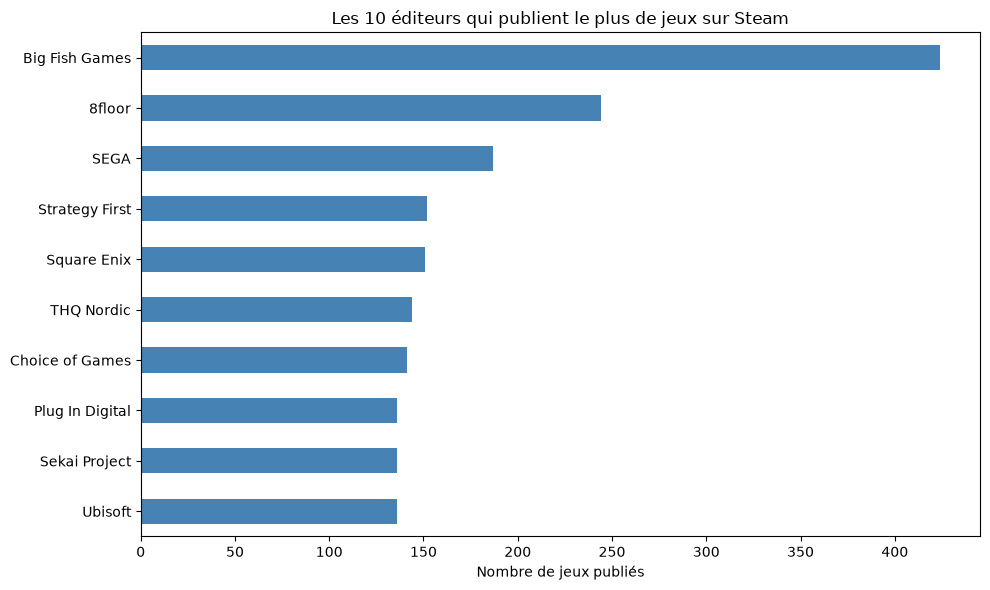

In [8]:
# Comptage sur la table normalisée (jeu, éditeur) : un jeu coédité compte pour chacun de ses
# éditeurs. On affiche 12 lignes pour rendre visibles les égalités autour du 10ᵉ rang.
classement_editeurs = (
    editeurs_jeux.groupBy("cle", "editeur")
    .agg(F.countDistinct("appid").alias("nb_jeux"))
    .orderBy(F.desc("nb_jeux"), "editeur")
)
classement_editeurs.select("editeur", "nb_jeux").show(12, truncate=False)
editeurs = classement_editeurs.limit(10).select("editeur", "nb_jeux")
dix_premiers = [ligne["cle"] for ligne in classement_editeurs.limit(10).collect()]
jeux_dix_premiers = (
    editeurs_jeux.filter(F.col("cle").isin(dix_premiers)).select("appid").distinct().count()
)
print(
    f"Jeux publiés par les 10 premiers éditeurs : {jeux_dix_premiers} "
    f"({jeux_dix_premiers / jeux.count():.1%} du catalogue)"
)
rang_ubisoft = (
    classement_editeurs.filter(
        F.col("nb_jeux")
        > premiere_ligne(classement_editeurs.filter(F.col("cle") == "ubisoft"))["nb_jeux"]
    ).count()
    + 1
)
print(f"Rang d'Ubisoft (1 + nombre d'éditeurs ayant strictement plus de jeux) : {rang_ubisoft}")
montrer(
    editeurs,
    "Les 10 éditeurs qui publient le plus de jeux sur Steam",
    "editeur",
    "nb_jeux",
    etiquette_x="Nombre de jeux publiés",
    etiquette_y="",
)

> **Interprétation** : le marché est extrêmement fragmenté. Le premier éditeur, Big Fish
> Games, ne publie que 424 jeux, et les dix premiers réunis en publient 1 851, soit 3,3 % du
> catalogue (55 690 jeux) ; on compte 29 434 éditeurs distincts une fois les noms
> normalisés. Ubisoft publie 136 jeux, à égalité au 8ᵉ rang avec Plug In Digital et Sekai
> Project (127 seulement sans regrouper ses écritures : la normalisation change son rang). La
> tête du classement mêle des éditeurs spécialisés dans les petits jeux « casual » (Big Fish
> Games, 8floor : section 4.3) et de grands éditeurs (SEGA, Square Enix, Ubisoft).

### 3.2 Quels sont les jeux les mieux notés ?

Classement par **borne basse de Wilson** (voir section 2), parmi les jeux d'au moins 500 avis.

In [9]:
mieux_notes = (
    jeux.filter(F.col("total_avis") >= 500)
    .orderBy(F.desc("score_wilson"))
    .select(
        "nom",
        "editeur",
        "total_avis",
        F.round("part_positive", 4).alias("part_positive"),
        F.round("score_wilson", 4).alias("score_wilson"),
    )
    .limit(10)
)
mieux_notes.show(truncate=False)
print("Jeux d'au moins 500 avis :", jeux.filter(F.col("total_avis") >= 500).count())
print("Nombre médian d'avis par jeu :", jeux.approxQuantile("total_avis", [0.5], 0.0)[0])

+-----------------------------------+---------------------------+----------+-------------+------------+
|nom                                |editeur                    |total_avis|part_positive|score_wilson|
+-----------------------------------+---------------------------+----------+-------------+------------+
|Flowers -Le volume sur ete-        |JAST USA                   |938       |0.9989       |0.994       |
|Aseprite                           |Igara Studio               |11903     |0.9933       |0.9916      |
|A Short Hike                       |adamgryu                   |11732     |0.9926       |0.9909      |
|Senren＊Banka                      |HIKARI FIELD, NekoNyan Ltd.|10677     |0.9921       |0.9903      |
|Aventura Copilului Albastru și Urât|Codrin Bradea              |2217      |0.9937       |0.9894      |
|People Playground                  |Studio Minus               |144569    |0.9886       |0.988       |
|Portal 2                           |Valve                      |

Nombre médian d'avis par jeu : 26.0


> **Interprétation** : classés par borne de Wilson, les jeux les mieux notés combinent une
> part d'avis positifs très élevée (plus de 98,7 %) et un volume d'avis suffisant pour qu'elle
> soit fiable : de très gros succès comme Portal 2 (309 441 avis, 98,8 % positifs), People
> Playground (144 569) ou Vampire Survivors (131 935) côtoient de petits jeux indépendants
> très appréciés (A Short Hike) et un logiciel de dessin (Aseprite). Sans cette correction, le
> classement serait occupé par des jeux à 100 % sur quelques dizaines d'avis : le nombre médian
> d'avis par jeu n'est que de 26, et seuls 7 767 jeux en ont au moins 500.

### 3.3 Y a-t-il des années avec plus de sorties ? Effet du Covid ?

+-----+----------+
|annee|nb_sorties|
+-----+----------+
| 1997|         2|
| 1998|         1|
| 1999|         3|
| 2000|         2|
| 2001|         4|
| 2002|         1|
| 2003|         3|
| 2004|         6|
| 2005|         6|
| 2006|        61|
| 2007|        98|
| 2008|       159|
| 2009|       311|
| 2010|       288|
| 2011|       267|
| 2012|       345|
| 2013|       471|
| 2014|      1557|
| 2015|      2575|
| 2016|      4185|
| 2017|      6017|
| 2018|      7678|
| 2019|      6968|
| 2020|      8305|
| 2021|      8823|
| 2022|      7455|
+-----+----------+

Dernière date de sortie du fichier : 2022-11-11


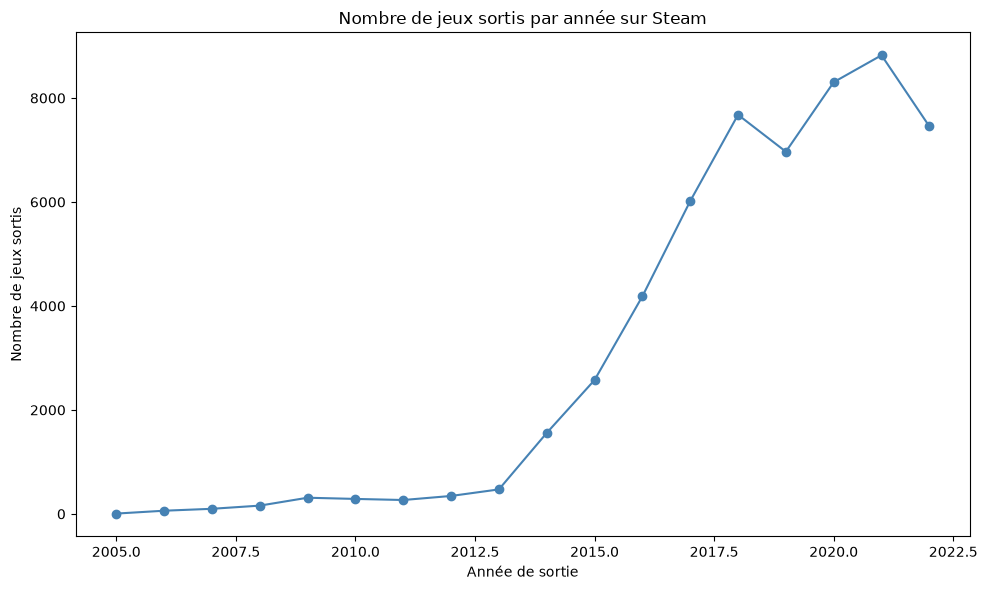

In [10]:
par_annee = (
    jeux.filter(F.col("annee").isNotNull())
    .groupBy("annee")
    .agg(F.count("*").alias("nb_sorties"))
    .orderBy("annee")
)
par_annee.show(40)
derniere_date = premiere_ligne(jeux.agg(F.max("date_sortie")))[0]
print("Dernière date de sortie du fichier :", derniere_date)
montrer(
    par_annee.filter(F.col("annee") >= 2005),
    "Nombre de jeux sortis par année sur Steam",
    "annee",
    "nb_sorties",
    type_graphique="line",
    etiquette_x="Année de sortie",
    etiquette_y="Nombre de jeux sortis",
)

 annee  nb_sorties  evolution_pct
  2013         471            NaN
  2014        1557          230.6
  2015        2575           65.4
  2016        4185           62.5
  2017        6017           43.8
  2018        7678           27.6
  2019        6968           -9.2
  2020        8305           19.2
  2021        8823            6.2
Hausse annuelle moyenne 2015-2018 (avant le creux de 2019) : +49.8 %
Moyenne annuelle 2018-2019 : 7323 ; 2020-2021 : 8564 (+16.9 %)


Mois où 2020 dépasse 2019 : 12 sur 12


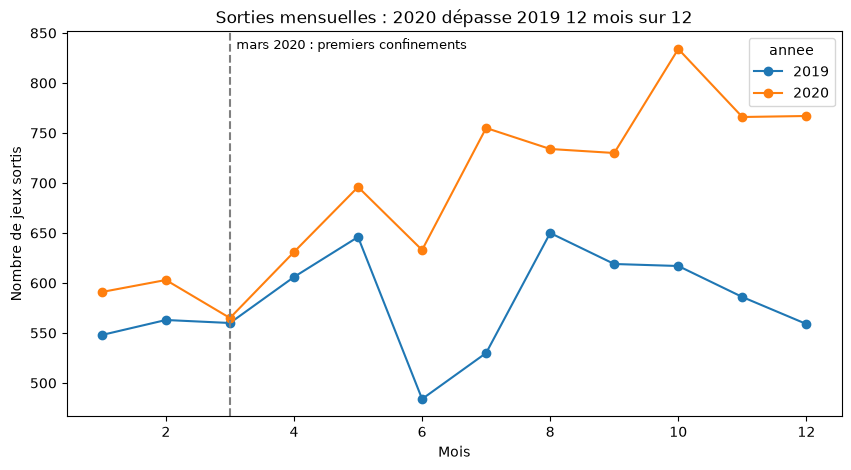

In [11]:
# Effet du Covid : on compare 2020-2021 (pandémie) à 2018-2019, en sorties par an et par mois,
# et on replace cette comparaison dans la tendance : une hausse en 2020 ne dit rien du Covid si
# les sorties augmentaient déjà autant chaque année avant.
covid = (
    jeux.filter(F.col("annee").between(2013, 2021))
    .groupBy("annee")
    .agg(F.count("*").alias("nb_sorties"))
    .orderBy("annee")
    .toPandas()
)
covid["evolution_pct"] = (covid["nb_sorties"].pct_change() * 100).round(1)
print(covid.to_string(index=False))
print(
    "Hausse annuelle moyenne 2015-2018 (avant le creux de 2019) :",
    f"{covid.loc[covid['annee'].between(2015, 2018), 'evolution_pct'].mean():+.1f} %",
)
moyenne_avant = covid.loc[covid["annee"].isin([2018, 2019]), "nb_sorties"].mean()
moyenne_pendant = covid.loc[covid["annee"].isin([2020, 2021]), "nb_sorties"].mean()
print(
    f"Moyenne annuelle 2018-2019 : {moyenne_avant:.0f} ; 2020-2021 : {moyenne_pendant:.0f} "
    f"({(moyenne_pendant / moyenne_avant - 1) * 100:+.1f} %)"
)

mensuel = (
    jeux.filter(F.col("annee").isin(2019, 2020))
    .groupBy("annee", "mois")
    .count()
    .toPandas()
    .pivot(index="mois", columns="annee", values="count")
)
ax = mensuel.plot(marker="o", figsize=(10, 5))
ax.axvline(3, color="gray", linestyle="--")
ax.text(3.1, mensuel.to_numpy().max(), "mars 2020 : premiers confinements", fontsize=9)
mois_au_dessus = int((mensuel[2020] > mensuel[2019]).sum())
print(f"Mois où 2020 dépasse 2019 : {mois_au_dessus} sur 12")
ax.set_title(f"Sorties mensuelles : 2020 dépasse 2019 {mois_au_dessus} mois sur 12")
ax.set_xlabel("Mois")
ax.set_ylabel("Nombre de jeux sortis")
plt.show()

> **Interprétation** : les sorties explosent à partir de 2014 (1 557 jeux, contre 471 en
> 2013), et atteignent 8 823 jeux en
> 2021. L'année 2022 est incomplète (dernière date du fichier : 11 novembre 2022) et ne doit pas
> être lue comme une baisse. Pendant le Covid, les sorties augmentent : +19,2 % en 2020, après
> un recul de 9,2 % en 2019, puis +6,2 % en 2021 ; 2020 dépasse 2019 chacun des douze mois.
> Mais il faut replacer ces chiffres dans la tendance : de 2015 à 2018, les sorties
> progressaient déjà de 50 % par an en moyenne, en ralentissant d'année en année (+65 %, +63 %,
> +44 %, +28 %). La hausse de 2020 ressemble donc davantage à une reprise après le creux de 2019
> qu'à une accélération. **Ces données ne permettent pas d'isoler un effet propre du Covid** :
> il faudrait une série plus longue et un modèle de la tendance ; un jeu se développe d'ailleurs
> en plusieurs années.

### 3.4 Comment les prix sont-ils distribués ? Les remises sont-elles fréquentes ?

Prix initial (USD) : déciles et centiles 10/25/50/75/90/99 % : [0.0, 1.99, 4.99, 9.99, 19.99, 44.99]


Jeux gratuits : 14.0% ; jeux en remise au moment de l'extraction : 4.5%


+------------------+------------------+
|remise_moyenne_pct|remise_mediane_pct|
+------------------+------------------+
| 57.58816521048451|                60|
+------------------+------------------+



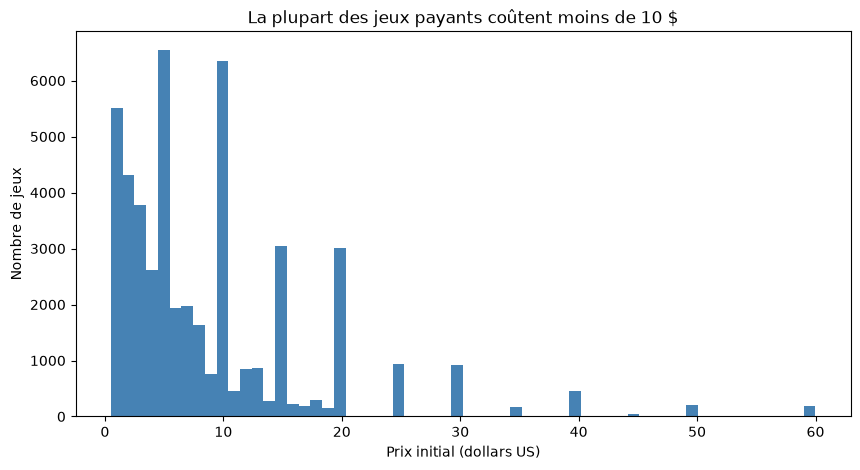

In [12]:
quantiles = jeux.approxQuantile("prix_initial_usd", [0.1, 0.25, 0.5, 0.75, 0.9, 0.99], 0.0)
print("Prix initial (USD) : déciles et centiles 10/25/50/75/90/99 % :", quantiles)
part_gratuits = jeux.filter(F.col("prix_initial_usd") == 0).count() / jeux.count()
part_remise = jeux.filter(F.col("remise_pct") > 0).count() / jeux.count()
print(
    f"Jeux gratuits : {part_gratuits:.1%} ; jeux en remise au moment de l'extraction : "
    f"{part_remise:.1%}"
)
jeux.filter(F.col("remise_pct") > 0).select(
    F.mean("remise_pct").alias("remise_moyenne_pct"),
    F.expr("percentile_approx(remise_pct, 0.5)").alias("remise_mediane_pct"),
).show()

# Histogramme des prix payants jusqu'à 60 $ (au-delà : logiciels professionnels, très rares).
prix_payants = (
    jeux.filter((F.col("prix_initial_usd") > 0) & (F.col("prix_initial_usd") <= 60))
    .select("prix_initial_usd")
    .toPandas()
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(prix_payants["prix_initial_usd"], bins=60, color="steelblue")
ax.set_title("La plupart des jeux payants coûtent moins de 10 $")
ax.set_xlabel("Prix initial (dollars US)")
ax.set_ylabel("Nombre de jeux")
plt.show()

> **Interprétation** : Steam est un marché de petits prix. Le prix initial médian est de
> 4,99 $ ; la moitié des jeux coûte entre 1,99 $ et 9,99 $, 90 % moins de 20 $ et 99 % moins de
> 45 $. Les prix se concentrent sur les seuils psychologiques en « ,99 ». 14,0 % des jeux sont
> gratuits. Au moment de l'extraction, seuls 4,5 % des jeux étaient en promotion, mais avec des
> remises fortes (57,6 % en moyenne, 60 % en médiane) : la remise est un événement ponctuel
> (soldes), pas un état permanent.

### 3.5 Quelles langues sont les plus représentées ?

+-------------------+-----+
|langue             |count|
+-------------------+-----+
|English            |55120|
|German             |14021|
|French             |13427|
|Russian            |12923|
|Simplified Chinese |12782|
|Spanish - Spain    |12235|
|Japanese           |10369|
|Italian            |9306 |
|Portuguese - Brazil|6750 |
|Korean             |6601 |
+-------------------+-----+



Part des jeux disponibles en français : 24.1%
Jeux proposés uniquement en anglais : 29163 (52.4%)


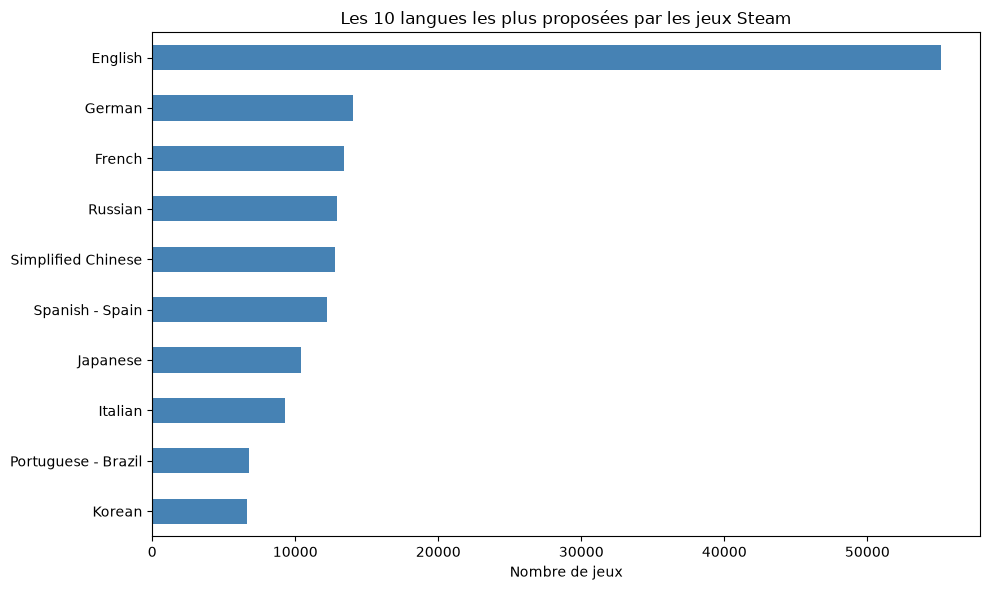

In [13]:
top_langues = langues.groupBy("langue").count().orderBy(F.desc("count")).limit(10)
top_langues.show(truncate=False)
print(
    f"Part des jeux disponibles en français : "
    f"{langues.filter(F.col('langue') == 'French').count() / jeux.count():.1%}"
)
anglais_seul = jeux.filter(F.trim("langues_texte") == "English").count()
print(f"Jeux proposés uniquement en anglais : {anglais_seul} ({anglais_seul / jeux.count():.1%})")
montrer(
    top_langues,
    "Les 10 langues les plus proposées par les jeux Steam",
    "langue",
    "count",
    etiquette_x="Nombre de jeux",
    etiquette_y="",
)

> **Interprétation** : l'anglais est quasi universel (55 120 jeux, 99 %). Viennent ensuite,
> très groupés, l'allemand (25,2 %), le français (24,1 %), le russe (23,2 %), le chinois
> simplifié (23,0 %) et l'espagnol (22,0 %), puis le japonais (18,6 %). Plus de la moitié des
> jeux (52,4 %) ne sont proposés qu'en anglais : la localisation reste un facteur de
> différenciation.

### 3.6 Combien de jeux sont interdits aux moins de 16 ou 18 ans ?

In [14]:
jeux.groupBy("age_requis").count().orderBy("age_requis").show(30)
interdits = jeux.filter(F.col("age_requis") >= 16).count()
print(f"Jeux réservés aux 16 ans et plus : {interdits} ({interdits / jeux.count():.2%})")

+----------+-----+
|age_requis|count|
+----------+-----+
|      NULL|    8|
|         0|55029|
|         3|    3|
|         5|    1|
|         6|    4|
|         7|    2|
|         8|    3|
|         9|    1|
|        10|    7|
|        12|   32|
|        13|   26|
|        14|   10|
|        15|  264|
|        16|   38|
|        17|   38|
|        18|  223|
|        20|    1|
+----------+-----+

Jeux réservés aux 16 ans et plus : 300 (0.54%)


> **Interprétation** : les jeux interdits aux mineurs sont très rares : 300 jeux sont réservés
> aux 16 ans et plus (0,54 % du catalogue), dont 223 aux 18 ans ; 98,8 % des jeux n'ont
> aucune restriction déclarée (âge 0). Cinq valeurs aberrantes (180, 35 ans) ont été écartées.
> Attention : « 0 » signifie souvent « non renseigné » plutôt que « tous publics » ; ce champ
> sous-estime probablement les restrictions réelles.

## 4. Analyse par genres

### 4.1 Quels genres sont les plus représentés ?

+---------------------+-------+
|genre                |nb_jeux|
+---------------------+-------+
|Indie                |39681  |
|Action               |23759  |
|Casual               |22086  |
|Adventure            |21431  |
|Strategy             |10895  |
|Simulation           |10836  |
|RPG                  |9534   |
|Early Access         |6145   |
|Free to Play         |3393   |
|Sports               |2666   |
|Racing               |2155   |
|Massively Multiplayer|1460   |
|Utilities            |682    |
|Design & Illustration|406    |
|Animation & Modeling |322    |
+---------------------+-------+



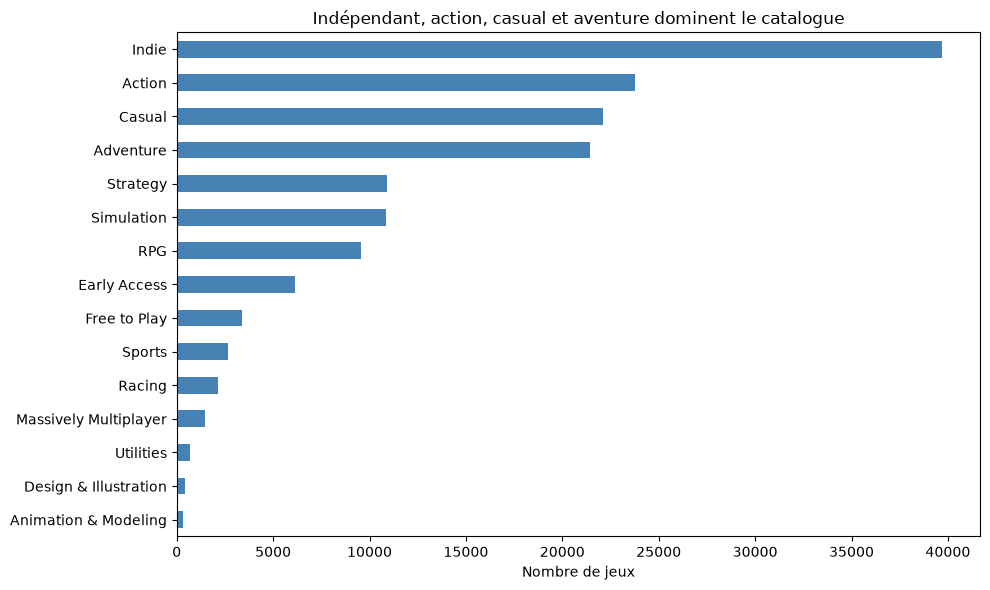

In [15]:
nb_par_genre = genres.groupBy("genre").agg(F.countDistinct("appid").alias("nb_jeux"))
top_genres = nb_par_genre.orderBy(F.desc("nb_jeux")).limit(15)
top_genres.show(truncate=False)
montrer(
    top_genres,
    "Indépendant, action, casual et aventure dominent le catalogue",
    "genre",
    "nb_jeux",
    etiquette_x="Nombre de jeux",
    etiquette_y="",
)

> **Interprétation** : « Indie » (indépendant) est présent dans 71 % des jeux (39 681), suivi
> de l'action (23 759), du casual (22 086) et de l'aventure (21 431) ; stratégie, simulation et
> RPG forment un second groupe (9 500 à 10 900 jeux). Un jeu porte en moyenne 2,8 genres
> (157 110 couples jeu-genre) : les genres se cumulent, d'où des totaux supérieurs au nombre
> de jeux.

### 4.2 Certains genres ont-ils un meilleur rapport d'avis positifs ?

Deux mesures complémentaires, sur les genres d'au moins 500 jeux : la part positive **de tous
les avis** du genre (dominée par les gros succès) et la part positive **médiane par jeu** (chaque
jeu compte pareil, parmi les jeux d'au moins 50 avis).

In [16]:
avis_genres = (
    genres.join(jeux.select("appid", "avis_positifs", "total_avis", "part_positive"), "appid")
    .groupBy("genre")
    .agg(
        F.countDistinct("appid").alias("nb_jeux"),
        (F.sum("avis_positifs") / F.sum("total_avis")).alias("part_positive_globale"),
        F.expr("percentile_approx(CASE WHEN total_avis >= 50 THEN part_positive END, 0.5)").alias(
            "part_positive_mediane"
        ),
    )
    .filter(F.col("nb_jeux") >= 500)
    .orderBy(F.desc("part_positive_mediane"))
)
avis_genres.select(
    "genre",
    "nb_jeux",
    F.round("part_positive_globale", 3).alias("part_positive_globale"),
    F.round("part_positive_mediane", 3).alias("part_positive_mediane"),
).show(truncate=False)

+---------------------+-------+---------------------+---------------------+
|genre                |nb_jeux|part_positive_globale|part_positive_mediane|
+---------------------+-------+---------------------+---------------------+
|Casual               |22086  |0.867                |0.819                |
|Adventure            |21431  |0.84                 |0.817                |
|Indie                |39681  |0.885                |0.813                |
|Action               |23759  |0.85                 |0.797                |
|RPG                  |9534   |0.856                |0.794                |
|Utilities            |682    |0.944                |0.784                |
|Simulation           |10836  |0.866                |0.783                |
|Strategy             |10895  |0.848                |0.781                |
|Racing               |2155   |0.859                |0.777                |
|Early Access         |6145   |0.822                |0.777                |
|Sports     

> **Interprétation** : parmi les genres d'au moins 500 jeux, la part médiane d'avis
> positifs varie peu (de 0,77 à 0,82) : casual, aventure et indépendant sont en tête (0,81 à
> 0,82). Le seul genre nettement en retrait est le massivement multijoueur (0,665 en médiane,
> 0,731 sur l'ensemble des avis) ; ces données ne disent pas pourquoi. « Early Access » et
> « Free to Play » ne sont pas des genres mais des modes de sortie ou de prix ; ils sont dans la
> moyenne basse (0,777 et 0,766), comme le sport (0,774). L'écart entre les deux mesures pour
> les utilitaires (0,944 contre 0,784) montre l'effet de quelques logiciels très populaires sur
> la mesure globale.

### 4.3 Les éditeurs ont-ils des genres favoris ?

Pour chacun des 10 éditeurs les plus prolifiques : son genre le plus fréquent et la part de son
catalogue que ce genre représente (fenêtre `Window` partitionnée par éditeur).

In [17]:
# Les 10 éditeurs les plus prolifiques (table normalisée, voir section 2), plus Ubisoft,
# client de l'étude, qu'il soit dans les dix premiers ou non.
editeurs_suivis = sorted(set(dix_premiers) | {"ubisoft"})
editeurs_top = editeurs_jeux.filter(F.col("cle").isin(editeurs_suivis)).select("appid", "editeur")
genre_editeur = (
    genres.join(editeurs_top, "appid")
    .groupBy("editeur", "genre")
    .agg(F.count("*").alias("nb_jeux"))
)
fenetre = Window.partitionBy("editeur").orderBy(F.desc("nb_jeux"), "genre")
favoris = (
    genre_editeur.join(
        editeurs_top.groupBy("editeur").agg(F.countDistinct("appid").alias("catalogue")),
        "editeur",
    )
    .withColumn("rang", F.row_number().over(fenetre))
    .filter(F.col("rang") == 1)
    .withColumn("part_du_catalogue", F.round(F.col("nb_jeux") / F.col("catalogue"), 2))
    .select("editeur", "genre", "nb_jeux", "catalogue", "part_du_catalogue")
    .orderBy(F.desc("catalogue"), "editeur")
)
favoris.show(truncate=False)

+---------------+--------+-------+---------+-----------------+
|editeur        |genre   |nb_jeux|catalogue|part_du_catalogue|
+---------------+--------+-------+---------+-----------------+
|Big Fish Games |Casual  |420    |424      |0.99             |
|8floor         |Casual  |244    |244      |1.0              |
|SEGA           |Action  |88     |187      |0.47             |
|Strategy First |Strategy|52     |152      |0.34             |
|Square Enix    |Action  |84     |151      |0.56             |
|THQ Nordic     |Action  |68     |144      |0.47             |
|Choice of Games|RPG     |140    |141      |0.99             |
|Plug In Digital|Indie   |100    |136      |0.74             |
|Sekai Project  |Casual  |103    |136      |0.76             |
|Ubisoft        |Action  |75     |136      |0.55             |
+---------------+--------+-------+---------+-----------------+



> **Interprétation** : deux profils d'éditeurs se distinguent. Les spécialistes consacrent la
> quasi-totalité de leur catalogue à un genre : Big Fish Games (99 % casual), 8floor (100 %
> casual), Choice of Games (99 % RPG). Les grands éditeurs sont diversifiés : l'action ne
> représente que 47 % du catalogue de SEGA et de THQ Nordic, 55 % de celui d'Ubisoft et 56 % de
> celui de Square Enix.

### 4.4 Quels genres sont les plus lucratifs ?

Le fichier ne contient **pas de chiffre de ventes**. Deux mesures, chacune avec sa limite :

- **taille du marché** : revenu brut estimé du genre, *prix initial × point milieu de la
  tranche de propriétaires*, sommé sur ses jeux. Ordre de grandeur seulement (tranches larges,
  remises, part de Steam non déduite) ; un jeu à plusieurs genres compte dans chacun, donc les
  totaux des genres se recouvrent ; les jeux gratuits valent 0 par construction ;
- **chances de succès d'un jeu payant** : part des jeux payants du genre dont la tranche
  commence à **1 million de propriétaires**, avec son intervalle de confiance de Wilson à 95 %.

Pourquoi pas le « revenu médian par jeu » ? Parce que 71 % des jeux payants sont dans la
tranche la plus basse (0 à 20 000 propriétaires) : la médiane vaut alors *prix × 10 000*, et
plusieurs genres tombent exactement sur la même valeur. Ce serait classer des genres sur un
effet de découpage des tranches, pas sur leur rentabilité.

Jeux payants dans la tranche 0 à 20 000 propriétaires : 71%


Somme des revenus estimés des genres : 235 Md$ ; total réel sans double compte : 96.7 Md$
                genre  nb_jeux  revenu_total_mds_usd  nb_payants  nb_succes  part_succes_pct  ic95_bas_pct  ic95_haut_pct
               Action    23759                 62.50       20582        490             2.38          2.18           2.60
            Adventure    21431                 39.87       19019        276             1.45          1.29           1.63
                Indie    39681                 34.00       34765        280             0.81          0.72           0.90
                  RPG     9534                 29.91        8140        174             2.14          1.85           2.48
             Strategy    10895                 20.97        9386        165             1.76          1.51           2.04
           Simulation    10836                 19.48        9451        153             1.62          1.38           1.89
               Casual    22086                  8.40    

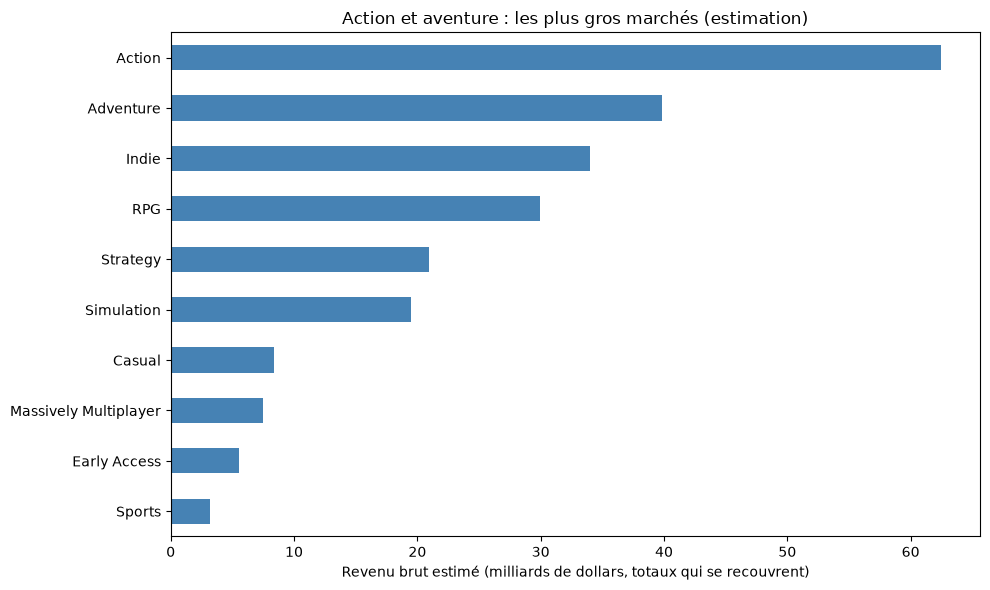

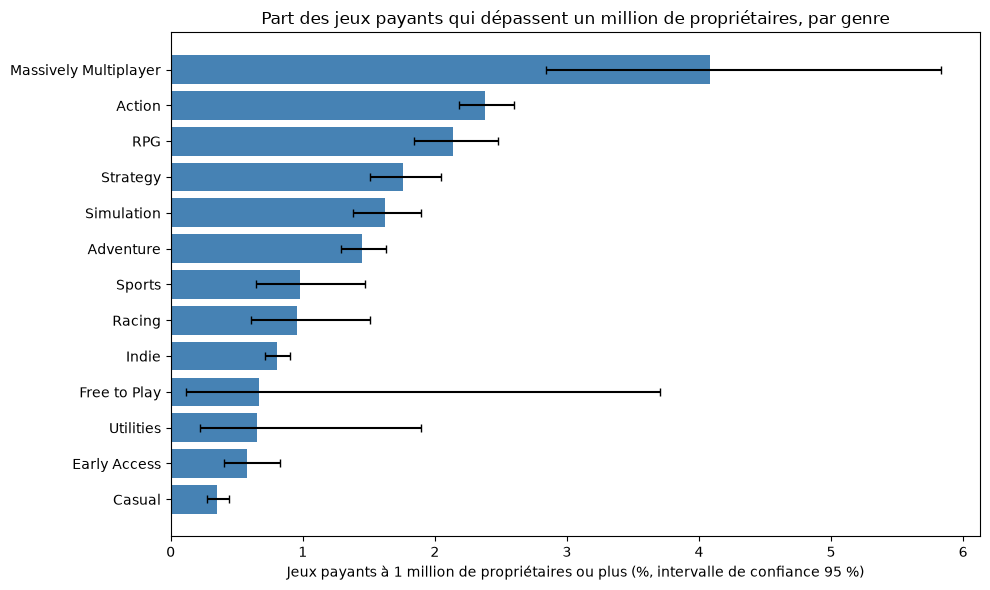

In [18]:
revenus_jeux = jeux.select(
    "appid",
    "prix_initial_usd",
    (F.col("prix_initial_usd") * F.col("proprietaires_milieu")).alias("revenu_estime"),
    (F.col("proprietaires_min") >= 1_000_000).cast("int").alias("succes"),
)
total_sans_double_compte = premiere_ligne(revenus_jeux.agg(F.sum("revenu_estime")))[0] / 1e9
part_tranche_basse = premiere_ligne(
    jeux.filter(F.col("prix_initial_usd") > 0).select(
        F.mean((F.col("proprietaires_max") <= 20_000).cast("int"))
    )
)[0]
print(f"Jeux payants dans la tranche 0 à 20 000 propriétaires : {part_tranche_basse:.0%}")

lucratifs = (
    genres.join(revenus_jeux, "appid")
    .groupBy("genre")
    .agg(
        F.countDistinct("appid").alias("nb_jeux"),
        (F.sum("revenu_estime") / 1e9).alias("revenu_total_mds_usd"),
        F.sum(F.when(F.col("prix_initial_usd") > 0, 1).otherwise(0)).alias("nb_payants"),
        F.sum(F.when(F.col("prix_initial_usd") > 0, F.col("succes")).otherwise(0)).alias(
            "nb_succes"
        ),
    )
    .filter(F.col("nb_jeux") >= 500)
    .orderBy(F.desc("revenu_total_mds_usd"))
)
table_lucratifs = lucratifs.toPandas()  # 20 lignes au plus : le calcul lourd est déjà fait


# wilson (intervalle de confiance de Wilson d'une proportion) vient de steam_analyse.py.
table_lucratifs["part_succes_pct"] = (
    100 * table_lucratifs["nb_succes"] / table_lucratifs["nb_payants"]
)
bas, haut = wilson(table_lucratifs["nb_succes"], table_lucratifs["nb_payants"])
table_lucratifs["ic95_bas_pct"], table_lucratifs["ic95_haut_pct"] = 100 * bas, 100 * haut
print(
    f"Somme des revenus estimés des genres : {table_lucratifs['revenu_total_mds_usd'].sum():.0f} "
    f"Md$ ; total réel sans double compte : {total_sans_double_compte:.1f} Md$"
)
print(table_lucratifs.round(2).to_string(index=False))

montrer(
    lucratifs.limit(10),
    "Action et aventure : les plus gros marchés (estimation)",
    "genre",
    "revenu_total_mds_usd",
    etiquette_x="Revenu brut estimé (milliards de dollars, totaux qui se recouvrent)",
    etiquette_y="",
)

# Graphique des chances de succès, avec leurs intervalles : deux genres dont les intervalles se
# chevauchent largement ne doivent pas être départagés.
succes_tries = table_lucratifs.sort_values("part_succes_pct")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(succes_tries["genre"], succes_tries["part_succes_pct"], color="steelblue")
ax.errorbar(
    succes_tries["part_succes_pct"],
    succes_tries["genre"],
    xerr=[
        succes_tries["part_succes_pct"] - succes_tries["ic95_bas_pct"],
        succes_tries["ic95_haut_pct"] - succes_tries["part_succes_pct"],
    ],
    fmt="none",
    ecolor="black",
    capsize=3,
)
ax.set_title("Part des jeux payants qui dépassent un million de propriétaires, par genre")
ax.set_xlabel(
    "Jeux payants à 1 million de propriétaires ou plus (%, intervalle de confiance 95 %)"
)
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [19]:
# Combinaison de genres : l'action-RPG (jeux portant à la fois « Action » et « RPG ») fait-il
# mieux que l'action ou le RPG seuls ? Calcul direct de l'intersection, sur les jeux payants.
genres_listes = jeux.select(
    "appid", F.split(F.coalesce("genres_texte", F.lit("")), r",\s*").alias("liste_genres")
)
combinaisons = (
    genres_listes.join(revenus_jeux, "appid")
    .join(jeux.select("appid", "total_avis", "part_positive"), "appid")
    .withColumn("action", F.array_contains("liste_genres", "Action"))
    .withColumn("rpg", F.array_contains("liste_genres", "RPG"))
    .withColumn(
        "groupe",
        F.when(F.col("action") & F.col("rpg"), "action et RPG")
        .when(F.col("action"), "action sans RPG")
        .when(F.col("rpg"), "RPG sans action"),
    )
    .filter(F.col("groupe").isNotNull() & (F.col("prix_initial_usd") > 0))
    .groupBy("groupe")
    .agg(
        F.count("*").alias("nb_payants"),
        F.sum("succes").alias("nb_succes"),
        F.expr("percentile_approx(CASE WHEN total_avis >= 50 THEN part_positive END, 0.5)").alias(
            "part_positive_mediane"
        ),
    )
    .toPandas()
)
bas, haut = wilson(combinaisons["nb_succes"], combinaisons["nb_payants"])
combinaisons["part_succes_pct"] = 100 * combinaisons["nb_succes"] / combinaisons["nb_payants"]
combinaisons["ic95_bas_pct"], combinaisons["ic95_haut_pct"] = 100 * bas, 100 * haut
print(combinaisons.round(3).to_string(index=False))

         groupe  nb_payants  nb_succes  part_positive_mediane  part_succes_pct  ic95_bas_pct  ic95_haut_pct
  action et RPG        3346        107                  0.788            3.198         2.653          3.850
action sans RPG       17236        383                  0.811            2.222         2.012          2.453
RPG sans action        4794         67                  0.822            1.398         1.102          1.771


In [20]:
# Contrôle indispensable : le prix. Les jeux d'action-RPG sont-ils plus souvent de gros succès
# parce qu'ils sont des action-RPG, ou parce qu'ils sont plus chers (gros budgets) ? On compare
# les trois groupes À GAMME DE PRIX ÉGALE (même découpage qu'en section 6).
prix_et_groupes = (
    genres_listes.join(revenus_jeux, "appid")
    .withColumn("action", F.array_contains("liste_genres", "Action"))
    .withColumn("rpg", F.array_contains("liste_genres", "RPG"))
    .withColumn(
        "groupe",
        F.when(F.col("action") & F.col("rpg"), "action et RPG")
        .when(F.col("action"), "action sans RPG")
        .when(F.col("rpg"), "RPG sans action"),
    )
    .filter(F.col("groupe").isNotNull() & (F.col("prix_initial_usd") > 0))
    .withColumn(
        "gamme_prix",
        F.when(F.col("prix_initial_usd") < 5, "1 moins de 5 $")
        .when(F.col("prix_initial_usd") < 10, "2 de 5 à 10 $")
        .when(F.col("prix_initial_usd") < 20, "3 de 10 à 20 $")
        .when(F.col("prix_initial_usd") < 40, "4 de 20 à 40 $")
        .otherwise("5 40 $ et plus"),
    )
)
print("Prix initial médian des jeux payants, par groupe :")
prix_et_groupes.groupBy("groupe").agg(
    F.expr("percentile_approx(prix_initial_usd, 0.5)").alias("prix_median_usd")
).orderBy("groupe").show()
par_gamme = (
    prix_et_groupes.groupBy("gamme_prix", "groupe")
    .agg(F.count("*").alias("nb_payants"), F.sum("succes").alias("nb_succes"))
    .orderBy("gamme_prix", "groupe")
    .toPandas()
)
bas, haut = wilson(par_gamme["nb_succes"], par_gamme["nb_payants"])
par_gamme["part_succes"] = (
    (100 * par_gamme["nb_succes"] / par_gamme["nb_payants"]).round(1).astype(str)
    + " % ["
    + (100 * bas).round(1).astype(str)
    + " ; "
    + (100 * haut).round(1).astype(str)
    + "] (n = "
    + par_gamme["nb_payants"].astype(str)
    + ")"
)
print("Part de jeux payants à 1 million de propriétaires ou plus, à gamme de prix égale :")
print(par_gamme.pivot(index="gamme_prix", columns="groupe", values="part_succes").to_string())

Prix initial médian des jeux payants, par groupe :


+---------------+---------------+
|         groupe|prix_median_usd|
+---------------+---------------+
|RPG sans action|           7.99|
|  action et RPG|           9.99|
|action sans RPG|           5.99|
+---------------+---------------+



Part de jeux payants à 1 million de propriétaires ou plus, à gamme de prix égale :
groupe                       RPG sans action                  action et RPG                 action sans RPG
gamme_prix                                                                                                 
1 moins de 5 $  0.3 % [0.1 ; 0.6] (n = 1901)   0.4 % [0.2 ; 1.0] (n = 1191)    0.3 % [0.2 ; 0.4] (n = 8465)
2 de 5 à 10 $   1.1 % [0.7 ; 1.8] (n = 1271)    1.8 % [1.1 ; 3.0] (n = 865)    1.2 % [1.0 ; 1.6] (n = 4496)
3 de 10 à 20 $  2.4 % [1.7 ; 3.4] (n = 1219)    4.4 % [3.2 ; 5.9] (n = 961)    4.5 % [3.8 ; 5.2] (n = 3387)
4 de 20 à 40 $   4.3 % [2.6 ; 7.1] (n = 323)  11.3 % [8.1 ; 15.6] (n = 275)  14.5 % [12.1 ; 17.2] (n = 740)
5 40 $ et plus   6.2 % [2.7 ; 13.8] (n = 80)  24.1 % [14.6 ; 36.9] (n = 54)  28.4 % [21.7 ; 36.1] (n = 148)


> **Interprétation** : en **taille de marché** (revenu brut estimé, totaux qui se
> recouvrent : 235 Md$ pour les genres, 96,7 Md$ sans double compte), l'action domine (environ
> 62 Md$), devant l'aventure (40), l'indépendant (34), le RPG (30) et la stratégie (21). En
> **chances de succès** d'un jeu payant (au moins un million de propriétaires), le
> massivement multijoueur arrive en tête (4,1 %, intervalle de 2,8 à 5,8 %, sur 686 jeux
> payants seulement), puis l'action (2,4 %) et le RPG (2,1 %), dont les intervalles se
> chevauchent ; l'indépendant (0,8 %) et surtout le casual (0,35 %) en sont loin : beaucoup de
> jeux, peu de gros succès. Pour le croisement **action et RPG**, la part brute de gros succès
> (3,2 %, de 2,7 à 3,9 %) dépasse celle de l'action sans RPG (2,2 %) et du RPG sans action
> (1,4 %) ; mais **c'est surtout un effet de prix** : les action-RPG payants coûtent plus cher
> (prix médian 9,99 $, contre 5,99 $ pour l'action seule et 7,99 $ pour le RPG seul), et les
> jeux chers réussissent plus souvent (section 6). **À gamme de prix égale**, l'action-RPG ne
> fait pas mieux que l'action seule (entre 20 et 40 $ : 11,3 % contre 14,5 %, intervalles qui
> se chevauchent) ; en revanche, l'action, avec ou sans RPG, fait nettement mieux que le RPG
> seul au-dessus de 20 $ (entre 20 et 40 $ : 14,5 % et 11,3 % contre 4,3 % ; au-delà de 40 $ :
> 28,4 % et 24,1 % contre 6,2 % ; intervalles disjoints). La part médiane d'avis positifs de
> l'action-RPG est un peu plus basse (0,79 contre 0,81 et 0,82). Ce sont des associations
> observées, pas des causes.

## 5. Analyse par plateformes

### 5.1 La plupart des jeux sont-ils disponibles sur Windows, Mac ou Linux ?

        part_des_jeux
windows       99.97 %
mac           22.93 %
linux         15.19 %


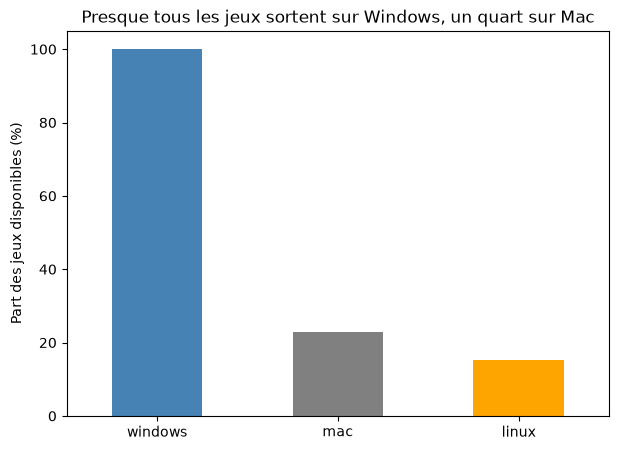

In [21]:
plateformes = (
    jeux.select(
        F.mean(F.col("windows").cast("int")).alias("windows"),
        F.mean(F.col("mac").cast("int")).alias("mac"),
        F.mean(F.col("linux").cast("int")).alias("linux"),
    )
    .toPandas()
    .T
)
plateformes.columns = ["part_des_jeux"]
print((plateformes * 100).round(2).astype(str) + " %")
ax = (plateformes["part_des_jeux"] * 100).plot.bar(
    color=["steelblue", "gray", "orange"], figsize=(7, 5)
)
ax.set_title("Presque tous les jeux sortent sur Windows, un quart sur Mac")
ax.set_ylabel("Part des jeux disponibles (%)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.show()

> **Interprétation** : Windows est la plateforme de référence (99,97 % des jeux) ; le Mac
> (22,9 %) et Linux (15,2 %) restent minoritaires. Sortir sur Windows est indispensable ; Mac et
> Linux sont des marchés d'appoint.

### 5.2 Certains genres sont-ils plus souvent disponibles sur certaines plateformes ?

In [22]:
genre_plateforme = (
    genres.join(jeux.select("appid", "mac", "linux"), "appid")
    .groupBy("genre")
    .agg(
        F.count("*").alias("nb_jeux"),
        F.round(F.mean(F.col("mac").cast("int")), 3).alias("part_mac"),
        F.round(F.mean(F.col("linux").cast("int")), 3).alias("part_linux"),
    )
    .filter(F.col("nb_jeux") >= 500)
    .orderBy(F.desc("part_mac"))
)
genre_plateforme.show(truncate=False)

+---------------------+-------+--------+----------+
|genre                |nb_jeux|part_mac|part_linux|
+---------------------+-------+--------+----------+
|Strategy             |10895  |0.276   |0.168     |
|Indie                |39681  |0.25    |0.176     |
|Free to Play         |3393   |0.249   |0.14      |
|RPG                  |9534   |0.236   |0.16      |
|Adventure            |21431  |0.235   |0.154     |
|Casual               |22086  |0.232   |0.15      |
|Simulation           |10836  |0.225   |0.141     |
|Racing               |2155   |0.197   |0.141     |
|Action               |23759  |0.192   |0.142     |
|Sports               |2666   |0.19    |0.108     |
|Massively Multiplayer|1460   |0.185   |0.112     |
|Utilities            |682    |0.15    |0.072     |
|Early Access         |6145   |0.146   |0.103     |
+---------------------+-------+--------+----------+



> **Interprétation** : la stratégie est le genre le plus souvent porté sur Mac (27,6 %) et
> l'indépendant sur Linux (17,6 %). L'accès anticipé (14,6 % sur Mac) et les utilitaires (7,2 %
> sur Linux) le sont le moins : un jeu inachevé se concentre d'abord sur Windows. Les écarts
> entre grands genres restent modérés (19 à 28 % sur Mac).

## 6. Analyse multivariée : qu'est-ce qui accompagne la popularité ?

Le nombre de propriétaires, d'avis et de joueurs simultanés suivent des distributions très
asymétriques (quelques énormes succès, des dizaines de milliers de jeux confidentiels) : on
calcule les corrélations de Pearson sur leur **logarithme** (`log1p`), pour qu'elles ne soient
pas dictées par une poignée de valeurs extrêmes. Trois précautions de lecture : (1) la matrice
porte sur les jeux d'au moins 50 avis (un pourcentage d'avis positifs sur 3 avis n'a pas de
sens) ; (2) SteamSpy n'observe pas les ventes : ses tranches de propriétaires sont des
**estimations**, dont la méthode n'est pas documentée dans le jeu fourni ; si elles s'appuient
en partie sur le nombre d'avis, leur corrélation avec les avis est en partie mécanique ;
(3) la remise est un instantané (95,5 % des jeux n'en ont aucune ce jour-là) : une corrélation
faible avec la remise ne dit presque rien de l'effet des soldes.

                        prix_initial_usd  remise_pct  part_positive  log_avis  \
prix_initial_usd                    1.00        0.02           0.12      0.29   
remise_pct                          0.02        1.00          -0.01      0.01   
part_positive                       0.12       -0.01           1.00      0.23   
log_avis                            0.29        0.01           0.23      1.00   
log_joueurs_simultanes              0.40        0.04           0.25      0.78   
log_proprietaires                   0.10        0.02           0.07      0.85   
nb_langues                          0.19        0.04           0.10      0.31   

                        log_joueurs_simultanes  log_proprietaires  nb_langues  
prix_initial_usd                          0.40               0.10        0.19  
remise_pct                                0.04               0.02        0.04  
part_positive                             0.25               0.07        0.10  
log_avis                       

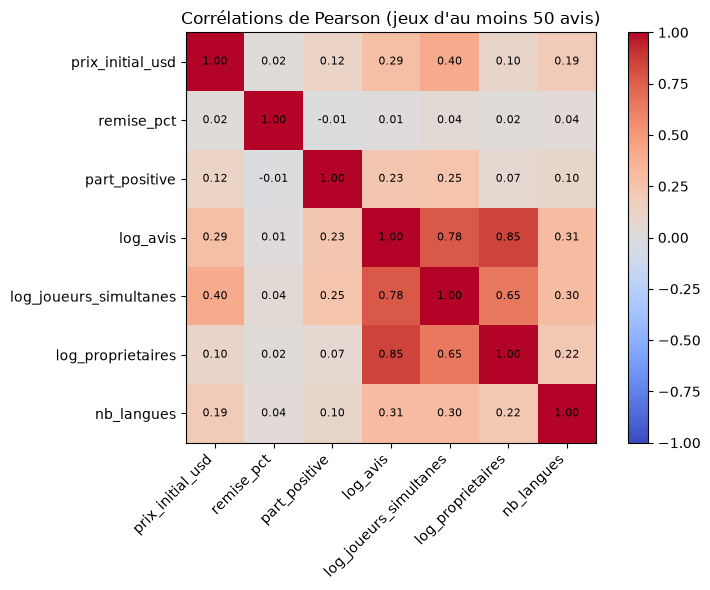

In [23]:
colonnes_corr = {
    "prix_initial_usd": F.col("prix_initial_usd"),
    "remise_pct": F.col("remise_pct").cast(DoubleType()),
    "part_positive": F.col("part_positive"),
    "log_avis": F.log1p("total_avis"),
    "log_joueurs_simultanes": F.log1p("joueurs_simultanes"),
    "log_proprietaires": F.log1p("proprietaires_milieu"),
    "nb_langues": F.col("nb_langues").cast(DoubleType()),  # balises retirées (section 2)
}
table_corr = jeux.filter(F.col("total_avis") >= 50).select(
    [expression.alias(nom) for nom, expression in colonnes_corr.items()]
)
noms = list(colonnes_corr)
# DataFrame.stat.corr calcule une corrélation de Pearson par paire, en parallèle sur les
# partitions ; 21 paires pour 7 variables.
matrice = pd.DataFrame(1.0, index=noms, columns=noms)
for i, a in enumerate(noms):
    for b in noms[i + 1 :]:
        matrice.loc[a, b] = matrice.loc[b, a] = table_corr.stat.corr(a, b)
print(matrice.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(matrice, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(noms)), noms, rotation=45, ha="right")
ax.set_yticks(range(len(noms)), noms)
for i in range(len(noms)):
    for j in range(len(noms)):
        ax.text(j, i, f"{matrice.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image)
ax.set_title("Corrélations de Pearson (jeux d'au moins 50 avis)")
plt.tight_layout()
plt.show()

In [24]:
# Popularité selon la gamme de prix : part des jeux à au moins 1 million de propriétaires (avec
# intervalle de Wilson) et part d'avis positifs médiane. Le nombre MÉDIAN de propriétaires n'est
# pas montré : il vaut le milieu de la tranche la plus basse pour presque toutes les gammes et ne
# discrimine rien (même effet de découpage qu'en 4.4).
gammes = (
    jeux.withColumn(
        "gamme_prix",
        F.when(F.col("prix_initial_usd") == 0, "0 gratuit")
        .when(F.col("prix_initial_usd") < 5, "1 moins de 5 $")
        .when(F.col("prix_initial_usd") < 10, "2 de 5 à 10 $")
        .when(F.col("prix_initial_usd") < 20, "3 de 10 à 20 $")
        .when(F.col("prix_initial_usd") < 40, "4 de 20 à 40 $")
        .otherwise("5 40 $ et plus"),
    )
    .groupBy("gamme_prix")
    .agg(
        F.count("*").alias("nb_jeux"),
        # Nombre de jeux dont la tranche commence à 1 million de propriétaires (succès massifs).
        F.sum((F.col("proprietaires_min") >= 1_000_000).cast("int")).alias("nb_succes"),
        F.expr("percentile_approx(part_positive, 0.5)").alias("part_positive_mediane"),
    )
    .orderBy("gamme_prix")
)
table_gammes = gammes.toPandas()  # six lignes
bas, haut = wilson(table_gammes["nb_succes"], table_gammes["nb_jeux"])
table_gammes["part_succes_pct"] = 100 * table_gammes["nb_succes"] / table_gammes["nb_jeux"]
table_gammes["ic95_bas_pct"], table_gammes["ic95_haut_pct"] = 100 * bas, 100 * haut
print(table_gammes.round(3).to_string(index=False))
print(
    "Jeux sans remise au moment de l'extraction :",
    f"{(jeux.filter(F.col('remise_pct') == 0).count() / jeux.count()):.1%}",
)

    gamme_prix  nb_jeux  nb_succes  part_positive_mediane  part_succes_pct  ic95_bas_pct  ic95_haut_pct
     0 gratuit     7779        277                  0.736            3.561         3.171          3.996
1 moins de 5 $    22742         58                  0.786            0.255         0.197          0.330
 2 de 5 à 10 $    12688        108                  0.814            0.851         0.706          1.027
3 de 10 à 20 $     9375        304                  0.825            3.243         2.903          3.621
4 de 20 à 40 $     2512        203                  0.812            8.081         7.078          9.212
5 40 $ et plus      594         75                  0.799           12.626        10.193         15.540
Jeux sans remise au moment de l'extraction : 95.5%


> **Interprétation** : les trois mesures de popularité vont ensemble (corrélations des
> logarithmes : propriétaires et avis 0,85, en partie par construction si les estimations de
> propriétaires dérivent des avis ; joueurs simultanés et avis 0,78). Le prix est modérément
> lié aux joueurs simultanés (0,40) et aux avis (0,29) : les jeux chers sont plus souvent des
> productions ambitieuses. Le nombre de langues accompagne aussi la popularité (0,22 à 0,31).
> La qualité perçue (part d'avis positifs) n'est que faiblement liée au succès (0,07 à 0,25).
> Par gamme de prix, la part de très gros succès (au moins un million de propriétaires) croît
> avec le prix payant : 0,26 % sous 5 $, 0,85 % de 5 à 10 $, 3,2 % de 10 à 20 $, 8,1 % de 20 à
> 40 $ (intervalle de 7,1 à 9,2 %) et 12,6 % au-delà (10,2 à 15,5 %) ; les jeux gratuits sont à
> 3,6 %. Ce sont des corrélations, pas des causes : un gros budget explique à la fois un prix
> élevé, une localisation étendue et une audience large.

## 7. Efficacité du traitement parallélisé

**Expérience.** Le champ `tags` est une structure de 441 colonnes (votes des joueurs par
étiquette : « Open World », « Multiplayer »...). Le « déplier » en lignes (une ligne par jeu et
par tag voté) puis agréger les votes par tag représente 55 691 × 441 ≈ 24,6 millions de cellules
à examiner : c'est la partie la plus lourde de l'étude. On exécute **le même calcul Spark**
avec 1, 2, 4, 8, 16 partitions et autant de partitions que de cœurs disponibles : une partition
est traitée par un seul cœur à la fois. Pour chaque réglage : un essai de chauffe (chargement
des classes Java), puis **cinq essais chronométrés, tous affichés** ; on retient la **médiane**,
moins sensible qu'une moyenne à un essai ralenti par une autre tâche de la machine. Enfin, on
obtient le même résultat avec **pandas**, par un autre chemin (somme directe de chaque colonne,
sans dépliage), et on vérifie que les 441 totaux sont identiques.

In [25]:
noms_tags = [champ.name for champ in champs_struct(brut.schema, "data", "tags")]
# votes_par_tag (déplie les 441 tags en lignes puis somme les votes) et chronometrer (une
# préparation en cache, un essai de chauffe, puis les essais chronométrés) sont dans
# steam_analyse.py.

coeurs = spark.sparkContext.defaultParallelism
reglages = reglages_partitions(coeurs)
essais_par_reglage = {p: chronometrer(brut, noms_tags, p) for p in reglages}
mesures = tableau_acceleration(essais_par_reglage)
print(f"Cœurs disponibles : {coeurs}")
print(mesures.round(2).to_string())

Cœurs disponibles : 24
            essai 1 (s)  essai 2 (s)  essai 3 (s)  essai 4 (s)  essai 5 (s)  médiane (s)  accélération
partitions                                                                                            
1                  3.93         3.91         3.75         3.74         3.59         3.75          1.00
2                  2.40         2.41         2.40         2.36         2.25         2.40          1.57
4                  1.66         1.67         1.62         1.69         1.73         1.67          2.25
8                  1.42         1.38         1.42         1.33         1.43         1.42          2.64
16                 1.36         1.27         1.39         1.44         1.37         1.37          2.73
24                 1.39         1.37         1.39         1.40         1.37         1.39          2.70


pandas (un cœur, données déjà en mémoire, somme par colonne) : 0.06 s


Totaux identiques pour les 441 tags (écart maximal : 0 vote)
Les 10 tags les plus votés :
Action          2911335
Adventure       2412383
Indie           2258563
Singleplayer    2169116
Casual          2007040
2D              1468241
Strategy        1398293
RPG             1322331
Simulation      1278811
Multiplayer     1211640


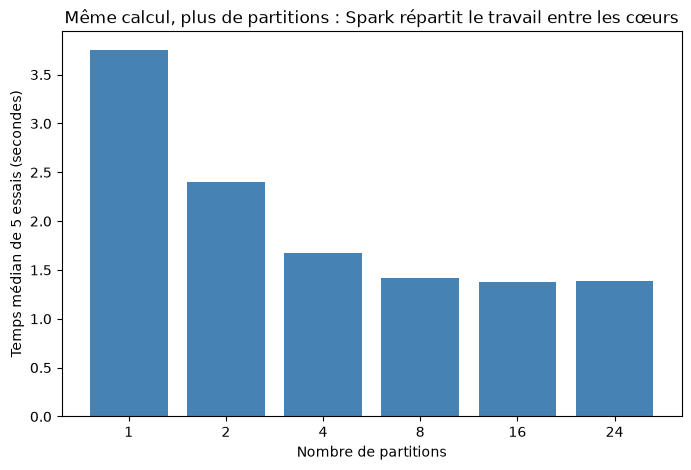

In [26]:
# Même résultat en pandas : chargement des tags en mémoire (hors chronomètre), puis somme de
# chaque colonne. Ce n'est PAS le même algorithme : pandas additionne directement les 441
# colonnes déjà alignées en mémoire, quand Spark déplie chaque jeu en lignes puis regroupe.
tags_pandas = pd.DataFrame(brut.select("data.tags.*").toPandas())
debut = time.perf_counter()
votes_pandas = tags_pandas.sum()
duree_pandas = time.perf_counter() - debut
print(f"pandas (un cœur, données déjà en mémoire, somme par colonne) : {duree_pandas:.2f} s")

# Contrôle complet : pour chacun des 441 tags, le total des votes doit être identique dans les
# deux moteurs (et pas seulement l'ordre des dix premiers).
resultat_spark = (
    votes_par_tag(brut.select("data.tags"), noms_tags).toPandas().set_index("tag")["votes"]
)
# comparer_votes REFUSE (ValueError) un nombre de tags ou un total différent entre les deux moteurs.
comparaison = comparer_votes(resultat_spark, votes_pandas, noms_tags)
ecarts = (comparaison["spark"] - comparaison["pandas"]).abs()
print(
    f"Totaux identiques pour les {len(comparaison)} tags (écart maximal : {ecarts.max():.0f} vote)"
)
print("Les 10 tags les plus votés :")
print(comparaison["spark"].sort_values(ascending=False).head(10).astype(int).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar([str(p) for p in mesures.index], mesures["médiane (s)"], color="steelblue")
ax.set_title("Même calcul, plus de partitions : Spark répartit le travail entre les cœurs")
ax.set_xlabel("Nombre de partitions")
ax.set_ylabel("Temps médian de 5 essais (secondes)")
plt.show()

In [27]:
# Plan physique du calcul : on y lit l'opérateur Generate (explode), l'agrégation partielle par
# partition (HashAggregate) puis l'échange entre partitions (Exchange) avant l'agrégation finale :
# la mécanique « map-reduce » qui rend le calcul parallélisable.
tampon = io.StringIO()
with contextlib.redirect_stdout(tampon):
    votes_par_tag(brut.select("data.tags"), noms_tags).explain()
# Le plan cite le chemin absolu du fichier sur la machine qui l'exécute, parfois tronqué par
# Spark (« ... ») : on remplace tout, de « file: » jusqu'au nom du fichier ou jusqu'à la
# troncature, par le chemin relatif au dossier du projet (le chemin peut contenir des espaces).
# plan_sans_chemin_de_machine REFUSE (ValueError) un plan où un chemin de machine subsiste.
plan = plan_sans_chemin_de_machine(tampon.getvalue())
print(plan)

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[tag#104171], functions=[sum(votes#104172L), count(1)])
   +- Exchange hashpartitioning(tag#104171, 8), ENSURE_REQUIREMENTS, [plan_id=12660]
      +- HashAggregate(keys=[tag#104171], functions=[partial_sum(votes#104172L), partial_count(1)])
         +- Project [paire#104169.tag AS tag#104171, paire#104169.votes AS votes#104172L]
            +- Filter isnotnull(paire#104169.votes)
               +- Generate explode(array(struct(tag, 1980s, votes, tags#103284.1980s), struct(tag, 1990's, votes, tags#103284.1990's), struct(tag, 2.5D, votes, tags#103284.2.5D), struct(tag, 2D, votes, tags#103284.2D), struct(tag, 2D Fighter, votes, tags#103284.2D Fighter), struct(tag, 2D Platformer, votes, tags#103284.2D Platformer), struct(tag, 360 Video, votes, tags#103284.360 Video), struct(tag, 3D, votes, tags#103284.3D), struct(tag, 3D Fighter, votes, tags#103284.3D Fighter), struct(tag, 3D Platformer, votes, tags#103284.3D Pla

> **Interprétation** : le même calcul (24,6 millions de cellules dépliées puis agrégées) est
> nettement plus rapide quand Spark le répartit sur plusieurs partitions : en temps médian de
> cinq essais (valeurs du tableau ci-dessus), 3,75 s avec une partition, 2,40 s avec deux
> (× 1,57), 1,67 s avec quatre (× 2,25), 1,42 s avec huit (× 2,64) et 1,37 s avec seize
> (× 2,73) ; avec 24 partitions, autant que de cœurs, plus aucun gain (1,39 s). Le gain
> reste loin du nombre de partitions, car une part du
> travail ne se parallélise pas (lancement des tâches, échange des résultats partiels entre
> partitions, visible dans le plan (`Exchange`), agrégation finale) : c'est
> la loi d'Amdahl ; et au-delà d'un certain point, le coût d'organisation de tâches plus
> nombreuses et plus petites annule le gain. Le plan affiché (cellule 43, plan non final)
> prévoit 8 partitions de brassage ; à l'exécution, l'exécution adaptative de Spark peut les
> regrouper. Les essais d'un même réglage varient (de 3,59 à
> 3,93 s pour une partition) et les accélérations changent d'une exécution à l'autre selon la
> charge de la machine : d'où la médiane, et les cinq essais affichés.
>
> pandas obtient les mêmes 441 totaux de votes (vérifié tag par tag) en 0,06 s, mais **par un
> autre algorithme** : il additionne directement des colonnes déjà alignées en mémoire, sans
> rien déplier. Ce n'est donc pas une course à armes égales : l'expérience montre que Spark
> répartit un calcul lourd entre les cœurs, pas qu'il bat pandas sur un fichier de 64 Mo. Spark
> se justifie quand les données dépassent la mémoire d'une machine : le même code s'exécute
> alors sur un cluster (Databricks) en répartissant les partitions entre plusieurs machines, ce
> que pandas ne sait pas faire.

## 8. Recommandations pour Ubisoft et limites

**Recommandations pour Ubisoft** : chacune reliée à un résultat ; ce sont des pistes
fondées sur des associations observées, à confirmer par des tests (prix, bêta, A/B sur la page
Steam) avant d'engager un budget.

1. **Privilégier un jeu d'action, avec ou sans composante RPG, plutôt qu'un RPG pur** : à gamme
   de prix égale, la part de gros succès (au moins un million de propriétaires) de l'action
   dépasse nettement celle du RPG seul au-dessus de 20 $ (entre 20 et 40 $ : 14,5 % pour
   l'action seule, 11,3 % pour l'action-RPG, 4,3 % pour le RPG seul ; section 4.4) ; ajouter
   une composante RPG à un jeu d'action n'apporte pas d'avantage démontré. Éviter les marchés
   les plus encombrés et les moins porteurs : l'indépendant (39 681 jeux, 0,8 % de gros
   succès) et le casual (22 086 jeux, 0,35 %).
2. **Ne pas craindre un prix premium pour un jeu à gros budget** : la part de gros succès croît
   avec le prix (8,1 % entre 20 et 40 $, 12,6 % au-delà, contre 0,26 % sous 5 $ ; section 6).
   C'est une corrélation : un prix élevé accompagne un gros budget, il ne le remplace pas. Le
   prix exact se fixe par des tests.
3. **Localiser largement dès la sortie** : plus de la moitié des jeux n'existent qu'en
   anglais ; allemand, français, russe, chinois simplifié, espagnol et japonais sont les langues
   les plus offertes par les concurrents, et le nombre de langues accompagne la popularité
   (section 3.5 et 6).
4. **Sortir d'abord sur Windows** (99,97 % des jeux), le Mac (23 %) et Linux (15 %) venant
   ensuite (section 5).
5. **Si le jeu est massivement multijoueur, soigner l'expérience en ligne dès le lancement** :
   c'est le seul genre nettement en retrait sur les avis (0,665 en médiane contre 0,77 à 0,82
   pour les autres ; section 4.2), alors qu'il a la plus forte part de gros succès (4,1 %) :
   un public large mais exigeant.
6. **Prévoir un budget de visibilité** : plus de 8 000 jeux sont sortis par an en 2020 et 2021 ; dans un
   catalogue aussi fragmenté (les dix premiers éditeurs ne publient que 3,3 % des jeux), la
   découvrabilité est le premier obstacle.

**Limites** : instantané du catalogue à novembre 2022 ; pas de chiffre de ventes (propriétaires
estimés par SteamSpy en tranches larges, prix au jour de l'extraction) ; les avis Steam ne
mesurent pas la qualité de façon neutre (auto-sélection des joueurs qui laissent un avis) ;
corrélations, pas causalités ; la normalisation des noms d'éditeurs est automatique et peut
laisser quelques variantes rares non regroupées.

## 9. Conformité RGPD

- **Nature des données** : catalogue public de jeux (titres, prix, genres, plateformes,
  agrégats d'avis). Aucune donnée sur des joueurs identifiables : les avis et les propriétaires
  sont des **compteurs agrégés**.
- **Point d'attention** : un éditeur ou un développeur indépendant peut être une **personne
  physique** ; son nom est alors une donnée personnelle (article 4.1 du RGPD), même publique.
  L'étude ne traite ces noms que pour des comptages et ne cherche aucune information sur les
  personnes : la finalité (étude de marché) est compatible et la minimisation respectée (ni
  site web, ni description, ni image ne sont gardés dans la table d'analyse).
- **Conservation** : le fichier source (63,7 Mo) n'est pas versionné dans ce dépôt ; il ne
  contient aucune donnée de joueur. Son nom, sa taille et son empreinte sont notés dans
  `donnees/LIRE_DONNEES.md`, pour vérifier la copie que l'on se procure avant d'exécuter le
  notebook.
- En production chez Ubisoft, croiser ces données avec des données de joueurs (comptes,
  achats) exigerait une base légale, une information des personnes et une analyse d'impact si
  le profilage est à grande échelle.

## 10. Exécution sur Databricks

Le notebook s'importe dans Databricks (menu *Import*), avec `steam_analyse.py` déposé dans le même dossier de l'espace de travail : la session Spark est choisie
automatiquement, l'adresse S3 du fichier est lue dans la variable d'environnement
`STEAM_CHEMIN_S3` (à définir avant l'exécution), et chaque graphique passe par `display()`, l'outil de
visualisation de Databricks demandé par l'énoncé. La publication de notebooks n'étant plus
disponible sur Databricks, **la consigne de l'étude de cas est de fournir des captures d'écran
des sorties de cellules**. Le dossier `captures/` contient les sorties de **l'exécution locale** de
ce notebook (graphiques). La branche Databricks (`display()`, lecture
S3) n'a pas été exécutée ici, faute d'espace de travail Databricks : elle est écrite et
commentée, mais non vérifiée. Si le notebook est importé dans Databricks Community, des
captures de `display()` pourront compléter ce dossier.

*Copyright © 2026 · Auteur : KinSushi · Enzo · Sovralys LLC*